# **Simulación del Modelo Daley-Kendall**

## 0. Introducción

Para llevar a cabo esta práctica de simulación, utilizaremos el modelo de Daley-Kendall para modelar la propagación de un rumor en una comunidad a través del siguiente sistema de ecuaciones diferenciales:

$$\frac{dU}{dt}=-\beta \frac{UD}{N},$$

$$\frac{dD}{dt}=\beta \frac{UD}{N} - \gamma \frac{D(2D+R)}{N},$$

$$\frac{dR}{dt}=\gamma \frac{D(2D+R)}{N},$$

$$\text{con } U(t)+D(t)+R(t)=N.$$

Donde $U(t)$ representa el número de personas que desconocen el rumor, $D(t)$ representa el número de personas que lo difunden y $R(t)$ representa el número de personas que lo conocen, pero han dejado de difundirlo. Asimismo, en el modelo se contemplan los siguientes parámetros:

$\beta >0$: Tasa de propagación del rumor

$\gamma >0$: Tasa de abandono de la difusión

Para el presente reporte se considerará el problema número 2 de la actividad 3; es decir, se tendrá en cuenta que hay una población de $N=2000$ y que una sola persona comienza a difundir el rumor. Por lo tanto, las condiciones iniciales son las siguientes:
$$U(0)=1999,\quad D(0)=1, \quad R(0)=0.$$

Y se considerarán como escenarios de simulación las nueve combinaciones de los siguientes valores que pueden tomar los parámetros $\beta$ y $\gamma$:
$$\beta \in \{0.2, 0.5, 1.0\}, \quad \gamma \in \{0.1, 0.3, 0.6\}.$$

Nuevamente, a través de solve_ivp(method='RK45') utilizaremos el método de Runge-Kutta para resolver los sistemas de ecuaciones diferenciales que surgen en cada escenario, mismo que se explicó en la práctica anterior.

## 1. Simulación de escenarios

Como primer punto, simularemos numéricamente el modelo con todas las combinaciones de valores de $\beta$ y $\gamma$ y graficaremos, pero antes de iniciar con las simulaciones, importamos las librerías que serán necesarias para nuestra práctica, estableceremos los parámetros necesarios y, adicionalmente, definiremos una función en la que estableceremos el modelo de Daley-Kendall.

In [ ]:
#Importación de librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp

In [ ]:
#Establecemos los parámetros del modelo
N = 2000
U0 = 1999
D0 = 1
R0 = 0
betas = [0.2, 0.5, 1.0]
gammas = [0.1, 0.3, 0.6]

#Establecemos un intervalo de simulación
t_inicio = 0
t_final = 100
num_puntos = 10001
t_eval = np.linspace(t_inicio, t_final, num_puntos)

In [ ]:
#Definimos el sistema de ecuaciones de Daley-Kendall de manera generalizada
def modelo_daley_kendall(t, y, beta, gamma, N):
    U, D, R = y
    dUdt = -beta * U * D / N
    dDdt = beta * U * D / N - gamma * D * (2 * D + R) / N
    dRdt = gamma * D * (2 * D + R) / N
    return [dUdt, dDdt, dRdt]

Una vez establecido el código inicial necesario, procedemos a realizar las nueve simulaciones y graficarlas. A lo largo del código usado para simular, se obtienen algunos valores y factores que serán de utilidad más adelante.

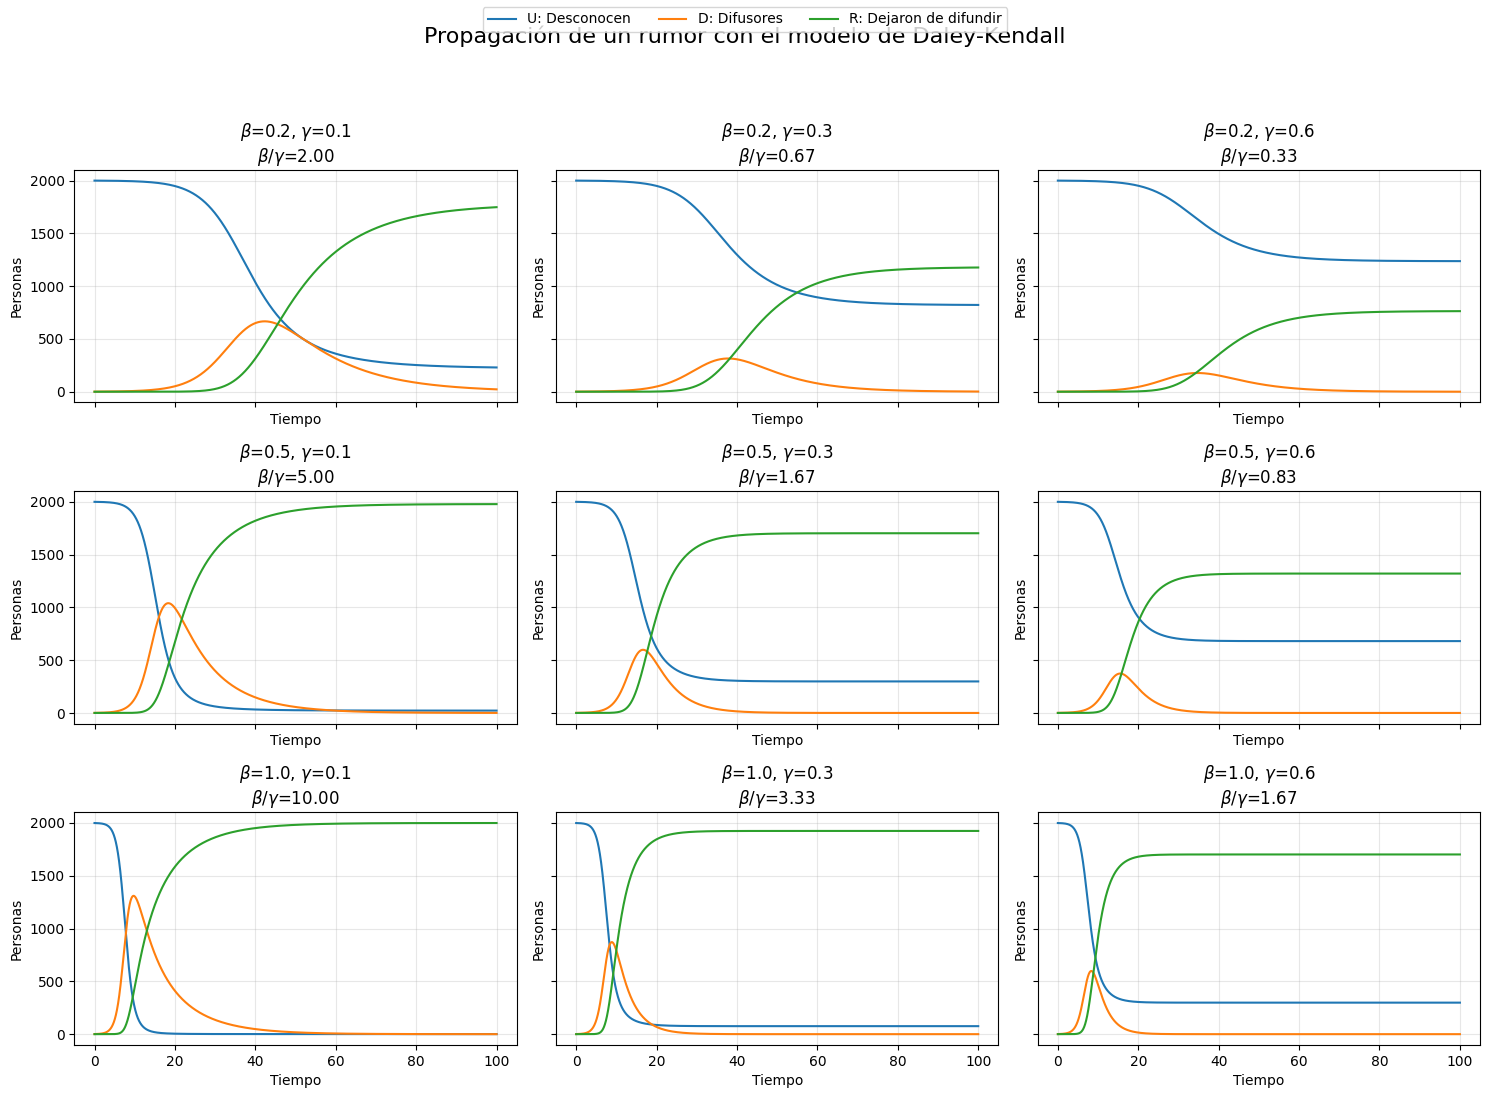

In [ ]:
#Creamos un diccionario para almacenar los resultados de cada combinación de beta y gamma
resultados = {}

#Hacemos un ciclo para simular todas las combinaciones de beta y gamma usando la función solve_ivp para resolver el sistema de ecuaciones diferenciales
for beta in betas:
    for gamma in gammas:
        solucion = solve_ivp(
            modelo_daley_kendall,
            [t_inicio, t_final],
            [U0, D0, R0],
            args=(beta, gamma, N),
            t_eval=t_eval,
            method='RK45',
            rtol=1e-8,
            atol=1e-10
        )
        resultados[(beta, gamma)] = solucion


#Creamos una lista para almacenar los resultados de cada combinación de beta y gamma
filas = []

#Hacemos un ciclo para calcular los resultados de cada combinación de beta y gamma
for beta in betas:
    for gamma in gammas:
        solucion = resultados[(beta, gamma)]
        U = solucion.y[0]
        D = solucion.y[1]
        R = solucion.y[2]
        t = solucion.t

        #Para cada combinación de beta y gamma, calculamos el máximo número de difusores y el tiempo en que ocurre
        indice_max = np.argmax(D)
        max_difusores = D[indice_max]
        tiempo_max = t[indice_max]

        #Obtenemos el número de personas que conocen el rumor al final (D+R) y el porcentaje de la población que representa
        alcance_final = D[-1] + R[-1]
        porcentaje_final = 100 * alcance_final / N

        filas.append({
            "Beta": beta,
            "Gamma": gamma,
            "Beta/Gamma": beta / gamma,
            "Máx. difusores": max_difusores,
            "Tiempo máx. difusores": tiempo_max,
            "Alcance final": alcance_final,
            "Porcentaje final": porcentaje_final
        })


#Almacenamos los resultados en un data frame de pandas para facilitar su manipulación y visualización
tabla_resultados = pd.DataFrame(filas)

#Creamos el gráfico de evolución temporal para cada combinación de beta y gamma
fig, axes = plt.subplots(
    len(betas),
    len(gammas),
    figsize=(15, 11),
    sharex=True,
    sharey=True
)

for i, beta in enumerate(betas):
    for j, gamma in enumerate(gammas):

        solucion = resultados[(beta, gamma)]

        t = solucion.t
        U = solucion.y[0]
        D = solucion.y[1]
        R = solucion.y[2]

        ax = axes[i, j]

        ax.plot(t, U, label="U: Desconocen")
        ax.plot(t, D, label="D: Difusores")
        ax.plot(t, R, label="R: Dejaron de difundir")

        ax.set_title(
            f"$\\beta$={beta}, $\\gamma$={gamma}\n"
            f"$\\beta/\\gamma$={beta/gamma:.2f}"
        )

        ax.set_xlabel("Tiempo")
        ax.set_ylabel("Personas")
        ax.grid(alpha=0.3)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3
)

fig.suptitle(
    "Propagación de un rumor con el modelo de Daley-Kendall",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


Si dividimos el conjunto de gráficas en columnas, podemos observar el efecto que tiene incrementar $\beta$ mientras $\gamma$ se mantiene constante. En las tres columnas podemos apreciar cómo el número de difusores, representado por la curva naranja, alcanza un máximo más alto conforme $\beta$ incrementa. De igual manera, vemos que el incremento de $\beta$ también provoca que esta curva se estreche y que el número de personas que desconocen el rumor caiga más rápido. Por otro lado, si analizamos los gráficos en forma de filas, podemos ver el efecto que tiene incrementar $\gamma$ mientras $\beta$ se mantiene constante. En las tres filas podemos apreciar que un incremento de $\gamma$ reduce el máximo de difusores alcanzado en cada escenario y que su curva se aplane. Otros efectos y relaciones entre $\beta$ y $\gamma$ serán analizados en las próximas secciones de la práctica.

## 2. Máximo de difusores, tiempo alcanzado y porcentaje final

Como segundo inciso, se presentará el máximo de difusores $D$ alcanzado para cada uno de los nueve escenarios simulados, el tiempo $t$ en el que se alcanza dicho valor y el porcentaje final de personas que conocen el rumor propagado. Estos datos fueron obtenidos en el proceso de simulación y almacenados en las variables $max\_difusores$, $tiempo\_max$ y $porcentaje\_final$ y guardados en columnas del data frame.

In [ ]:
#Ordenamos el data frame por el número de difusores
tabla_resultados = tabla_resultados.sort_values(
    ["Máx. difusores"], ascending=False
).reset_index(drop=True)

#Imprimimos la tabla de resultados con las columnas de interés
print(tabla_resultados[["Beta","Gamma","Máx. difusores","Tiempo máx. difusores", "Porcentaje final"]])

   Beta  Gamma  Máx. difusores  Tiempo máx. difusores  Porcentaje final
0   1.0    0.1     1309.766970                   9.72         99.965786
1   0.5    0.1     1039.342818                  18.35         98.886124
2   1.0    0.3      871.766179                   8.86         96.209382
3   0.2    0.1      666.666767                  42.31         88.505491
4   0.5    0.3      598.076234                  16.64         85.077076
5   1.0    0.6      598.076229                   8.32         85.077082
6   0.5    0.6      373.169072                  15.50         65.988543
7   0.2    0.3      314.815221                  37.81         58.909032
8   0.2    0.6      177.325014                  34.74         38.170826


En la tabla de resultados podemos observar numéricamente algo que se aprecia visualmente en las gráficas del inciso anterior. Podemos ver que el máximo de difusores y el alcance final en este intervalo de tiempo están fuertemente determinados por la razón $\beta / \gamma$. Por ejemplo, en el escenario donde $\beta=0.5$ y $\gamma=0.1$ existe una diferencia absoluta de $0.4$ entre ambas tasas y, a pesar de que esta diferencia es más pequeña que la diferencia de tasas del escenario donde $\beta=1.0$ y $\gamma=0.3$, se alcanza un mayor número de difusores en el primero, pues la relación $\beta / \gamma$ es mayor (5 > 3.33). El mismo efecto puede verse en los resultados del porcentaje final de personas que conocen el rumor al término del intervalo de tiempo: Un mayor porcentaje de personas conoce el rumor en el escenario $\beta=0.5$ y $\gamma=0.1$ que en el escenario $\beta=1.0$ y $\gamma=0.3$, a pesar de que $\beta$ es mucho más grande en el segundo.

Cabe mencionar que, si bien ya vimos que la razón $\beta / \gamma$ tiene una influencia importante en el número máximo de difusores, el tiempo en que se alcanza el máximo no se ve afectado de la misma manera por esta relación entre ambas tasas, ya que podemos ver que el escenario con el mayor número de difusores, que también es el de la mayor relación $\beta / \gamma$, no es aquel en el que se alcanza más rápido este máximo.

## 3. Mapa de calor del alcance final

Como tercer punto de la práctica, elaboraremos un mapa de calor del alcance final de la propagación del rumor en función de $\beta$ y $\gamma$. Para tal propósito, en el proceso de simulación de cada escenario se almacenó en la variable $alcance\_final$ el número de personas que conocen el rumor una vez finalizado el intervalo de tiempo de la simulación; es decir, $R+D$, mientras que en la variable $porcentaje\_final$ almacenamos el porcentaje que representan de la población total; es decir, $((R+D)/N)\cdot 100$.

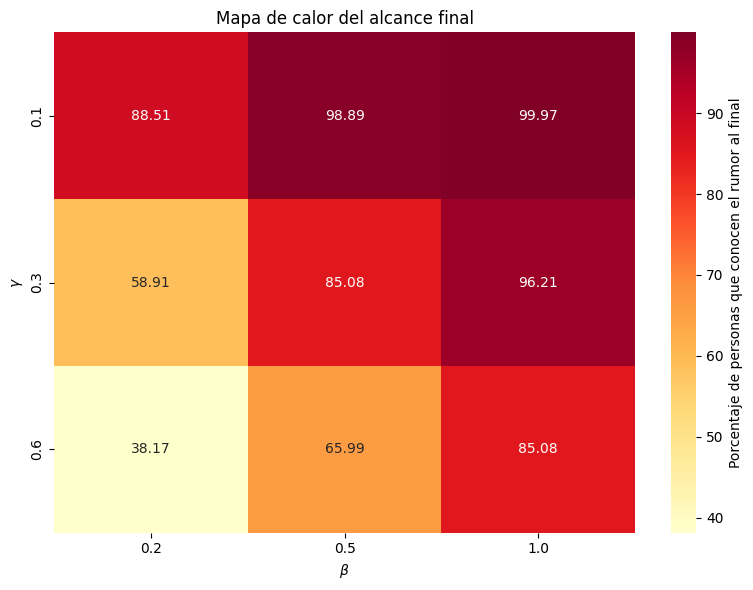

In [ ]:
#Creamos la matriz de alcance final para el mapa de calor
matriz_alcance = tabla_resultados.pivot(
    index="Gamma",
    columns="Beta",
    values="Porcentaje final"
)


#Creamos el mapa de calor del alcance final usando Seaborn y Matplotlib
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_alcance,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Porcentaje de personas que conocen el rumor al final"}
)

plt.title("Mapa de calor del alcance final")
plt.xlabel("$\\beta$")
plt.ylabel("$\\gamma$")

plt.tight_layout()
plt.show()

En la tabla del inciso anterior pudimos observar el efecto que tiene la relación $\beta/\gamma$ en el número máximo de difusores y en el porcentaje final de personas que conocen el rumor para cada escenario, efecto que ahora podemos visualizar gráficamente en un mapa de calor.

## 4. Escenarios con mayor alcance

En este cuarto inciso, mostraremos los resultados completos de los tres escenarios con el mayor alcance obtenido y explicaremos el papel que tiene la razón $\beta / \gamma$.

In [ ]:
#Seleccionamos a través de su índice los tres escenarios con el mayor alcance
indices_top3 = tabla_resultados["Porcentaje final"].nlargest(3).index
mayor_alcance = tabla_resultados.loc[indices_top3]

#Imprimimos los tres escenarios seleccionados
print("\nESCENARIOS CON MAYOR ALCANCE")
print(mayor_alcance.round(3))


ESCENARIOS CON MAYOR ALCANCE
   Beta  Gamma  Beta/Gamma  Máx. difusores  Tiempo máx. difusores  \
0   1.0    0.1      10.000        1309.767                   9.72   
1   0.5    0.1       5.000        1039.343                  18.35   
2   1.0    0.3       3.333         871.766                   8.86   

   Alcance final  Porcentaje final  
0       1999.316            99.966  
1       1977.722            98.886  
2       1924.188            96.209  


Como ya se mencionó anteriormente, vemos que los tres escenarios con el mayor número máximo de difusores y con el mayor alcance final también coinciden con tener la mayor razón $\beta/\gamma$. Esta razón representa el balance entre la velocidad con que el rumor se transmite $\beta$ y la velocidad con que los difusores dejan de propagarlo $\gamma$; por ello, no es necesario que $\beta$ y $\gamma$ estén muy alejadas en términos absolutos, sino que basta con que $\beta$ sea relativamente grande respecto a $\gamma$. Cuando $\beta/\gamma$ es alta, la incorporación de nuevas personas al grupo de difusores $D$ predomina relativamente sobre su salida hacia los que dejan de propagar el rumor $R$, permitiendo que se acumulen más difusores y que el rumor alcance a una mayor proporción de la población antes de que la difusión disminuya.

## 5. Comparación de dos escenarios con la misma razón $\beta / \gamma$

Por último, haremos una comparación entre dos escenarios que tengan la misma razón $\beta / \gamma$ y analizaremos su alcance final, el máximo de difusores alcanzado y el tiempo en el que llegan a él. Dentro de los escenarios simulados, los únicos que cumplen con tener la misma razón son el escenario $\beta=0.5$ y $\gamma=0.3$ y el escenario $\beta=1.0$ y $\gamma=0.6$.

In [ ]:
print("\nCOMPARACIÓN DE ESCENARIOS CON LA MISMA RAZÓN BETA/GAMMA")

for razon in sorted(tabla_resultados["Beta/Gamma"].unique()):

    grupo = tabla_resultados[
        np.isclose(tabla_resultados["Beta/Gamma"], razon)
    ]

    if len(grupo) > 1:

        print(f"\nRazón beta/gamma = {razon:.2f}")

        print(
            grupo[
                [
                    "Beta",
                    "Gamma",
                    "Máx. difusores",
                    "Tiempo máx. difusores",
                    "Porcentaje final"
                ]
            ].round(3).to_string(index=False)
        )


COMPARACIÓN DE ESCENARIOS CON LA MISMA RAZÓN BETA/GAMMA

Razón beta/gamma = 1.67
 Beta  Gamma  Máx. difusores  Tiempo máx. difusores  Porcentaje final
  0.5    0.3         598.076                  16.64            85.077
  1.0    0.6         598.076                   8.32            85.077


Comparando directamente estos dos escenarios con la misma razón $\beta / \gamma$, vemos que presentan prácticamente el mismo alcance final en este intervalo de tiempo y el mismo máximo de difusores, algo que ya podíamos intuir con base en el análisis realizado en los incisos previos; sin embargo, vemos que los tiempos en los que se alcanza el máximo sí difieren en ambos escenarios. La razón $\beta/\gamma$ determina principalmente el balance relativo entre la propagación y la pérdida de difusores, mientras que el tiempo depende de la velocidad absoluta a la que ocurren ambos procesos. Esto se puede ver si multiplicamos ambos parámetros por un mismo factor $k$. Si $\beta$ y $\gamma$ pasan a ser $\beta'=k\beta$ y $\gamma'=k\gamma$, la razón permanece igual:

$$
\frac{k\beta}{k\gamma}=\frac{\beta}{\gamma},
$$

por lo que el comportamiento relativo y, en particular, el alcance final se mantiene; sin embargo, las ecuaciones diferenciales pasan a ser:

$$\frac{dU}{dt}=-k\beta\frac{UD}{N},$$
$$\frac{dD}{dt}=k\left[\beta\frac{UD}{N}-\gamma\frac{D(2D+R)}{N}\right],$$
$$\frac{dR}{dt}=k\gamma \frac{D(2D+R)}{N}.$$

En otras palabras, las tasas de cambio modeladas por estas ecuaciones son $k$ veces más rápidas. Por lo tanto, el mismo proceso ocurre en una escala temporal aproximadamente $1/k$ veces menor. Por ejemplo, el primer escenario donde $\beta=0.5$ y $\gamma=0.3$ y el segundo escenario donde $\beta=1.0$ y $\gamma=0.6$ tienen la misma razón $\beta/\gamma=1.67$, pero en el segundo escenario ambas tasas son el doble, por lo que la propagación ocurre más rápidamente y el máximo de difusores se alcanza en un tiempo menor. Es decir, vemos que justamente en la comparación de estos dos escenarios tenemos un factor $k=2$ y, efectivamente, se cumple que la escala temporal del segundo escenario es $1/k = 1/2$ veces menor que la del primero, pues el máximo de difusores se alcanza justo en la mitad del tiempo.

## 6. Conclusiones

Como pudimos ver a través de las simulaciones realizadas, el hecho de incrementar el parámetro $\beta$ mientras $\gamma$ se mantiene constante provoca que se alcance un máximo de difusores más alto y que la curva que representa este valor se estreche; es decir, es más rápida la difusión. Por otro lado, incrementar $\gamma$ mientras $\beta$ se mantiene constante reduce el máximo de difusores alcanzado en cada escenario y desencadena que la curva que representa este valor se aplane; es decir, es más lento el proceso de la difusión.

De igual manera, pudimos apreciar la influencia que tiene la razón $\beta/\gamma$ dentro de los resultados de las simulaciones. Vimos que dos escenarios con la misma razón $\beta / \gamma$ tienen el mismo alcance final y el mismo máximo de difusores, ya que esta razón determina principalmente el balance relativo entre la propagación y la pérdida de difusores. No obstante, el tiempo de alcance máximo depende de la velocidad absoluta a la que ocurren los procesos. Si multiplicamos ambos parámetros por un mismo factor $k$, las tasas de cambio modeladas por las ecuaciones diferenciales del modelo son $k$ veces más rápidas, por lo que, un mismo proceso ocurre en una escala temporal aproximadamente $1/k$ veces menor, ocurriendo la propagación más rápidamente y alcanzándose el máximo de difusores en un tiempo menor.

## Archivo con código fuente

A continuación, se presenta el enlace de una carpeta de Google Drive en la que se encuentra
el archivo .ipynb en el cual se puede ejecutar todo el código presentado.

https://drive.google.com/drive/folders/1ePTtP9SjKEj3FoAXwg4YdbMKTkEOC8D4